# E-Commerce Sales & Customer Behavior Analysis — Exploratory Data Analysis

**Author:** Firhan Setyo
**Dataset:** E-commerce transaction data (2020–2024), 6 tables — `order_detail`, `customer_detail`, `payment_detail`, `product_detail`, `transaction_detail`, `funnel_detail`
**Tools:** Python (Pandas, Matplotlib, Seaborn)

This notebook explores customer demographics, payment behavior, order value distribution, and discount impact on purchase volume — independent of the SQL analysis (which focused on revenue trends, category performance, channel growth, and funnel conversion).

**Business questions explored in this notebook:**
1. Who are our customers? (age, customer type, geographic spread)
2. How do customers prefer to pay, and what does a typical order look like in value?
3. Does offering a discount actually drive customers to buy more per order?


## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


In [2]:
order = pd.read_csv('data/order_detail.csv', parse_dates=['order_date'])
customer = pd.read_csv('data/customer_detail.csv', parse_dates=['registration_date', 'dob'])
payment = pd.read_csv('data/payment_detail.csv')
product = pd.read_csv('data/product_detail.csv')
transaction = pd.read_csv('data/transaction_detail.csv', parse_dates=['transaction_date'])

print(f"order_detail: {order.shape}")
print(f"customer_detail: {customer.shape}")
print(f"payment_detail: {payment.shape}")
print(f"product_detail: {product.shape}")
print(f"transaction_detail: {transaction.shape}")


order_detail: (22812, 14)
customer_detail: (4657, 7)
payment_detail: (10, 2)
product_detail: (5000, 8)
transaction_detail: (13000, 10)


### Data quality check

In [3]:
print("Missing values per table:")
for name, df in [('order', order), ('customer', customer), ('transaction', transaction), ('product', product)]:
    n_missing = df.isnull().sum().sum()
    print(f"  {name}: {n_missing} missing values")

print(f"\nDuplicate transaction_ids in order_detail: {order['transaction_id'].duplicated().sum()} (expected — multiple line items per transaction)")
print(f"Duplicate customer_ids in customer_detail: {customer['customer_id'].duplicated().sum()}")


Missing values per table:
  order: 0 missing values
  customer: 0 missing values
  transaction: 0 missing values
  product: 0 missing values

Duplicate transaction_ids in order_detail: 9812 (expected — multiple line items per transaction)
Duplicate customer_ids in customer_detail: 0


## 2. Who Are Our Customers?

We look at customer type distribution and age, calculated from date of birth as of end of 2024 (the latest year in the dataset).

In [4]:
REFERENCE_DATE = pd.Timestamp('2024-12-31')
customer['age'] = ((REFERENCE_DATE - customer['dob']).dt.days / 365.25).astype(int)

print(customer['age'].describe())
print("\nCustomer type distribution:")
print(customer['customer_type'].value_counts())


count   4,657.00
mean       37.11
std        11.88
min        19.00
25%        26.00
50%        37.00
75%        47.00
max        64.00
Name: age, dtype: float64

Customer type distribution:
customer_type
Other            794
Undergraduate    787
Student          786
Entrepreneur     782
Professional     760
Teacher          748
Name: count, dtype: int64


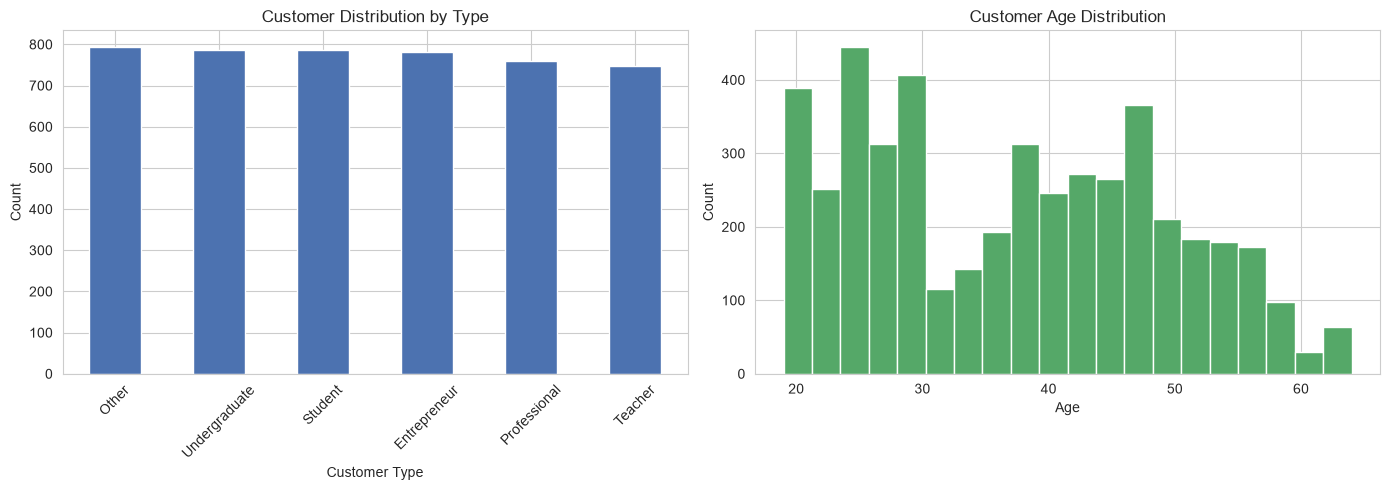

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

customer['customer_type'].value_counts().plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Customer Distribution by Type')
axes[0].set_xlabel('Customer Type')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

axes[1].hist(customer['age'], bins=20, color='#55A868', edgecolor='white')
axes[1].set_title('Customer Age Distribution')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('figures/01_customer_demographics.png', bbox_inches='tight')
plt.show()


**Insight:** Customer types are fairly evenly distributed across 6 segments (748–794 customers each), so no single segment dominates the user base. The age distribution shows a **noticeable spike around 23–25 years old** (~450 customers), which likely overlaps with the Student/Undergraduate segments — suggesting younger, education-affiliated customers are a meaningful chunk of the base and could be targeted with age-relevant campaigns (e.g. student discounts, campus partnerships).

## 3. Payment Behavior & Order Value Distribution

How do customers pay, and what does a "typical" order actually look like?

In [6]:
trx_merged = transaction.merge(payment, left_on='payment_method', right_on='id')

print("Transaction count by payment method:")
print(trx_merged['payment_method_y'].value_counts())

print("\nOrder value (total_paid) statistics:")
print(transaction['total_paid'].describe())


Transaction count by payment method:
payment_method_y
Digital Wallet              3210
Virtual Account             2543
QRIS Payment                2019
Over-the-Counter Payment    1308
Credit Card Payment         1298
Direct Debit Payment         673
Cash on Delivery COD         662
PayLater BNPL                650
Mobile Banking Payment       394
Interbank Transfer           243
Name: count, dtype: int64

Order value (total_paid) statistics:
count        13,000.00
mean      8,110,892.57
std      29,181,792.08
min               0.00
25%         403,321.22
50%       1,233,417.65
75%       3,922,386.27
max     484,269,676.00
Name: total_paid, dtype: float64


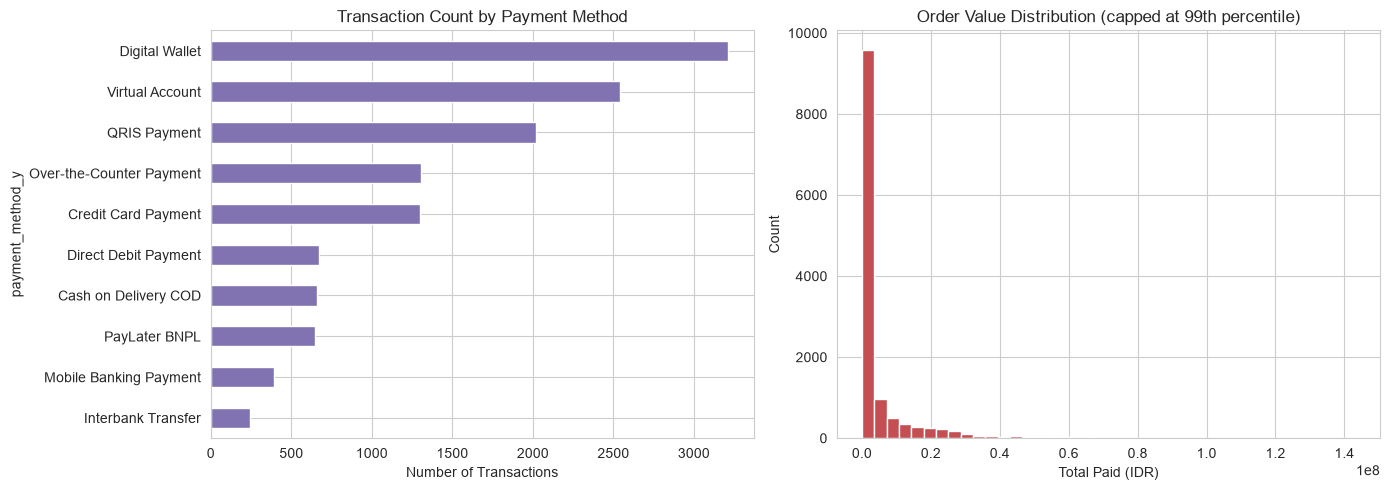

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pm_counts = trx_merged['payment_method_y'].value_counts()
pm_counts.plot(kind='barh', ax=axes[0], color='#8172B2')
axes[0].set_title('Transaction Count by Payment Method')
axes[0].set_xlabel('Number of Transactions')
axes[0].invert_yaxis()

cap = transaction['total_paid'].quantile(0.99)
axes[1].hist(transaction[transaction['total_paid'] <= cap]['total_paid'], bins=40, color='#C44E52', edgecolor='white')
axes[1].set_title('Order Value Distribution (capped at 99th percentile)')
axes[1].set_xlabel('Total Paid (IDR)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('figures/02_payment_aov.png', bbox_inches='tight')
plt.show()


**Insight:** **Digital Wallet** is the most-used payment method (3,210 transactions, ~25% of all transactions), followed by Virtual Account and QRIS — together these three digital-first methods account for the majority of payments, while Cash on Delivery is a relatively minor method (662 transactions) in this dataset.

The order value distribution is **heavily right-skewed**: the median order is **Rp 1,233,418**, but the mean is **Rp 8,110,893** — almost 6.5x higher — pulled up by a long tail of high-value transactions (up to Rp 484 million). This matters operationally: **median, not mean, should be used when describing a "typical" order**, since the mean is distorted by a small number of large transactions.

## 4. Does Discount Level Actually Drive Higher Purchase Volume?

A simple look at whether larger discounts correlate with customers buying more per order (a basic price-elasticity check).

In [8]:
order_v = order[order['is_valid'] == 1].copy()

order_v['discount_pct'] = np.where(
    order_v['before_discount'] > 0,
    order_v['discount_item'] / order_v['before_discount'] * 100,
    0
)

pct_no_discount = (order_v['discount_item'] == 0).mean() * 100
print(f"% of valid orders with ZERO discount: {pct_no_discount:.1f}%")
print("\nDiscount % distribution (non-zero only):")
print(order_v.loc[order_v['discount_pct'] > 0, 'discount_pct'].describe())


% of valid orders with ZERO discount: 80.3%

Discount % distribution (non-zero only):
count   4,265.00
mean       12.52
std         4.34
min         5.01
25%         8.67
50%        12.59
75%        16.37
max        19.99
Name: discount_pct, dtype: float64


  discount_bucket  avg_quantity  order_count
0              0%          6.14        17438
1            0-5%           NaN            0
2           5-10%          4.36         1433
3          10-20%          7.54         2832
4            20%+           NaN            0


C:\Users\firha\AppData\Local\Temp\ipykernel_472\931523603.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bucket_stats = order_v.groupby('discount_bucket').agg(


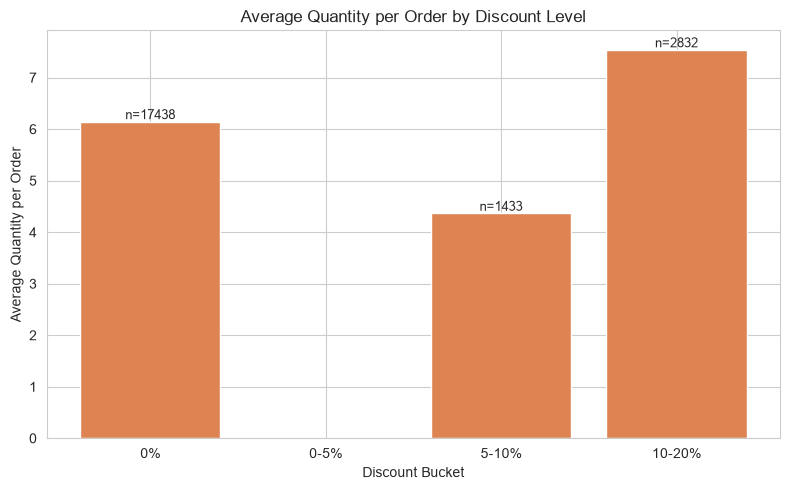

In [9]:
order_v['discount_bucket'] = pd.cut(
    order_v['discount_pct'],
    bins=[-0.01, 0, 5, 10, 20, 100],
    labels=['0%', '0-5%', '5-10%', '10-20%', '20%+']
)

bucket_stats = order_v.groupby('discount_bucket').agg(
    avg_quantity=('quantity', 'mean'),
    order_count=('order_id', 'count')
).reset_index()

print(bucket_stats)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(bucket_stats['discount_bucket'].astype(str), bucket_stats['avg_quantity'], color='#DD8452')
ax.set_title('Average Quantity per Order by Discount Level')
ax.set_xlabel('Discount Bucket')
ax.set_ylabel('Average Quantity per Order')
for bar, count in zip(bars, bucket_stats['order_count']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f'n={count}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('figures/03_discount_quantity.png', bbox_inches='tight')
plt.show()


**Insight:** **80.3% of valid orders received no discount at all**, and where discounts were applied, they topped out around 20%. Orders in the **10–20% discount bucket had the highest average quantity per order (7.5 units)**, compared to 6.1 units for orders with no discount — suggesting deeper discounts are associated with larger basket sizes. However, this segment is also much smaller (2,832 orders vs. 17,438 no-discount orders), so this directional signal would need a controlled test (e.g. A/B test) before being used to justify a broader discounting strategy.

## 5. Summary of Key Findings

| Area | Finding |
|---|---|
| Customer base | Evenly split across 6 customer types; notable age concentration at 23–25 years (Student/Undergraduate overlap) |
| Payment behavior | Digital Wallet is the leading payment method (~25% of transactions); COD is a minor method |
| Order value | Highly right-skewed — median (Rp 1.2M) is far more representative than mean (Rp 8.1M) |
| Discounting | 80% of orders get no discount; 10–20% discount orders show the highest average quantity, but sample size is small |

**Suggested next steps for the business:**
- Investigate whether the 23–25 age concentration correlates with specific product categories, to inform targeted campaigns.
- Run a controlled discount experiment (A/B test) on a larger sample before scaling 10–20% discounts, since the current signal is directional but not yet statistically validated.
- Standardize on median (not mean) when reporting "typical order value" in business dashboards to avoid overstating typical customer spend.
